# 02.3 · Measuring error: MAE, MSE, RMSE, R²

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/02-regression/03-measuring-error/lesson.ipynb)

Read the [README](README.md) first and fill the by-hand table. Here: the same table in NumPy, then scikit-learn's functions, then two experiments that show *why* the metrics disagree, then the real data.

## 1. The residual table

In [1]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import pandas as pd
five = pd.read_csv(data_path("shopwave_visits_spend_5.csv"))
five

,customer_id,visits_last_month,spend_next_month
0,C001,2,50
1,C002,4,80
2,C003,6,90
3,C004,8,130
4,C005,10,150


In [2]:
import numpy as np
x = five["visits_last_month"].to_numpy(dtype=float)
y = five["spend_next_month"].to_numpy(dtype=float)
y_hat = 12.5 * x + 25                     # the 02.2 line

resid = y - y_hat
table = pd.DataFrame({"y": y, "ŷ": y_hat, "y-ŷ": resid, "|y-ŷ|": np.abs(resid),
                      "(y-ŷ)²": resid**2, "y-ȳ": y - y.mean(), "(y-ȳ)²": (y - y.mean())**2})
display(table)
print("sums:", table[["|y-ŷ|", "(y-ŷ)²", "(y-ȳ)²"]].sum().to_dict())

,y,ŷ,y-ŷ,|y-ŷ|,(y-ŷ)²,y-ȳ,(y-ȳ)²
0,50.0,50.0,0.0,0.0,0.0,-50.0,2500.0
1,80.0,75.0,5.0,5.0,25.0,-20.0,400.0
2,90.0,100.0,-10.0,10.0,100.0,-10.0,100.0
3,130.0,125.0,5.0,5.0,25.0,30.0,900.0
4,150.0,150.0,0.0,0.0,0.0,50.0,2500.0


sums: {'|y-ŷ|': 20.0, '(y-ŷ)²': 150.0, '(y-ȳ)²': 6400.0}


In [3]:
n = len(y)
mae  = np.abs(resid).mean()
mse  = (resid**2).mean()
rmse = np.sqrt(mse)
ss_res = (resid**2).sum()
ss_tot = ((y - y.mean())**2).sum()
r2 = 1 - ss_res / ss_tot
print(f"MAE {mae:.2f}   MSE {mse:.2f}   RMSE {rmse:.3f}   R² = 1 - {ss_res:.0f}/{ss_tot:.0f} = {r2:.4f}")

MAE 4.00   MSE 30.00   RMSE 5.477   R² = 1 - 150/6400 = 0.9766


## 2. The same four numbers from scikit-learn

In [4]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
print("MAE ", mean_absolute_error(y, y_hat))
print("MSE ", mean_squared_error(y, y_hat))
print("RMSE", np.sqrt(mean_squared_error(y, y_hat)))
print("R²  ", r2_score(y, y_hat))

MAE  4.0
MSE  30.0
RMSE 5.477225575051661
R²   0.9765625


## 3. The baseline scores

Predict the mean (100) for everyone. R² is exactly 0 by construction: the model's squared error *is* the total squared error.

In [5]:
y_base = np.full(n, y.mean())
print(f"baseline  MAE {mean_absolute_error(y, y_base):.1f}   RMSE {np.sqrt(mean_squared_error(y, y_base)):.1f}   R² {r2_score(y, y_base):.3f}")

baseline  MAE 32.0   RMSE 35.8   R² 0.000


## 4. Experiment: one wholesaler

Add a sixth customer: 3 visits, £1,000 spend. Score the *same* line. Watch which metric moves most.

In [6]:
x6 = np.append(x, 3.0); y6 = np.append(y, 1000.0)
y_hat6 = 12.5 * x6 + 25
for name, a, b in [("MAE", mean_absolute_error(y, y_hat), mean_absolute_error(y6, y_hat6)),
                   ("RMSE", np.sqrt(mean_squared_error(y, y_hat)), np.sqrt(mean_squared_error(y6, y_hat6))),
                   ("R²", r2_score(y, y_hat), r2_score(y6, y_hat6))]:
    print(f"{name:<5} 5 customers: {a:8.2f}    6 customers: {b:8.2f}")

MAE   5 customers:     4.00    6 customers:   159.58
RMSE  5 customers:     5.48    6 customers:   382.77
R²    5 customers:     0.98    6 customers:    -0.29


One row out of six moved MAE from £4 to about £160 and RMSE from £5 to nearly £400: RMSE squares the £938 miss. R² went **negative**: with the wholesaler included, this line is worse than predicting the six-customer mean. This is why you report MAE *and* RMSE: their gap is an outlier detector.

## 5. Experiment: when R² goes negative

R² compares you to the mean. Predict something worse than the mean and R² is negative. Here, the median of a skewed target.

In [7]:
y_skew = np.array([10, 12, 15, 20, 500.])          # four small customers, one wholesaler
for name, guess in [("mean", y_skew.mean()), ("median", np.median(y_skew))]:
    pred = np.full(5, guess)
    print(f"predict the {name:<6} ({guess:6.1f}):  MAE {mean_absolute_error(y_skew, pred):6.1f}   R² {r2_score(y_skew, pred):7.3f}")

predict the mean   ( 111.4):  MAE  155.4   R²   0.000
predict the median (  15.0):  MAE   99.6   R²  -0.246


The median has a far better MAE and a *negative* R². Neither metric is lying: MAE asks "typically how far off?", R² asks "how much squared error compared with the mean?". For a skewed target they disagree, and you must decide which question the business is asking.

## 6. The real data

The 3,317-customer table (built in 01.9). Three predictors: the mean baseline, the median baseline, and a one-feature line fitted on past spend.

In [8]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import sys, pandas as pd
sys.path.insert(0, str(data_path("download.py").parent))
from download import ensure_online_retail

raw = pd.read_excel(ensure_online_retail(), sheet_name="Year 2010-2011")
print(raw.shape)
raw.head()


def clean_retail(df):
    """The standard ShopWave cleaning used from lesson 01.5 onwards."""
    out = df.copy()
    out = out[~out["Invoice"].astype(str).str.startswith("C")]   # drop cancellations
    out = out[(out["Quantity"] > 0) & (out["Price"] > 0)]         # drop returns / free items
    out = out.dropna(subset=["Customer ID"])                       # drop guest checkouts
    out = out.drop_duplicates()
    out["Customer ID"] = out["Customer ID"].astype(int)
    out["Revenue"] = out["Quantity"] * out["Price"]
    return out

sales = clean_retail(raw)
print(f"{len(raw):,} rows → {len(sales):,} after cleaning")


cutoff = pd.Timestamp("2011-09-01")
past = sales[sales["InvoiceDate"] < cutoff]
future = sales[(sales["InvoiceDate"] >= cutoff) & (sales["InvoiceDate"] < "2011-12-01")]

cust = past.groupby("Customer ID").agg(
    orders=("Invoice", "nunique"), spend=("Revenue", "sum"),
    products=("StockCode", "nunique"), items=("Quantity", "sum"),
    first_order=("InvoiceDate", "min"), last_order=("InvoiceDate", "max"),
    country=("Country", "first"))
cust["avg_order"] = cust["spend"] / cust["orders"]
cust["tenure_days"] = (cutoff - cust["first_order"]).dt.days
cust["days_since_last"] = (cutoff - cust["last_order"]).dt.days
cust["spend_next_quarter"] = future.groupby("Customer ID")["Revenue"].sum().reindex(cust.index).fillna(0)
cust = cust.drop(columns=["first_order", "last_order"])
print(f"{len(cust):,} customers; features from before {cutoff.date()}, target = spend Sep–Nov 2011")
cust.head()

(541910, 8)
541,910 rows → 392,693 after cleaning


3,317 customers; features from before 2011-09-01, target = spend Sep–Nov 2011


,orders,spend,products,items,country,avg_order,tenure_days,days_since_last,spend_next_quarter
Customer ID,,,,,,,,,
12346,1,77183.60,1,74215,United Kingdom,77183.600000,225,225,0.00
12347,5,2790.86,82,1590,Iceland,558.172000,267,29,1294.32
12348,3,1487.24,22,2124,Finland,495.746667,258,148,310.00
12350,1,334.40,17,197,Norway,334.400000,210,210,0.00
12352,5,1561.81,26,254,Norway,312.362000,196,162,944.23


In [9]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def report(name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    print(f"{name:<28} MAE £{mae:8.1f}   RMSE £{rmse:8.1f}   R² {r2:6.3f}")

from sklearn.linear_model import LinearRegression

y_real = cust["spend_next_quarter"]
line = LinearRegression().fit(cust[["spend"]], y_real)
print(f"line: spend_next ≈ {line.coef_[0]:.2f} × past_spend + {line.intercept_:.1f}\n")

report("baseline: mean", y_real, np.full(len(y_real), y_real.mean()))
report("baseline: median", y_real, np.full(len(y_real), y_real.median()))
report("line on past spend", y_real, line.predict(cust[["spend"]]))

line: spend_next ≈ 0.54 × past_spend + -71.1

baseline: mean               MAE £   951.3   RMSE £  3926.3   R²  0.000
baseline: median             MAE £   761.5   RMSE £  3972.7   R² -0.024
line on past spend           MAE £   547.1   RMSE £  2260.4   R²  0.669


The line cuts MAE and RMSE by about 40% and explains about two-thirds of the variation. The median baseline beats the mean baseline on MAE and loses on R²: the same disagreement as section 5, on real money.

(These scores are on the data the line was fitted to, so they are slightly optimistic. Module 04 fixes that.)

Finally, the plot you should always make: residuals against predictions.

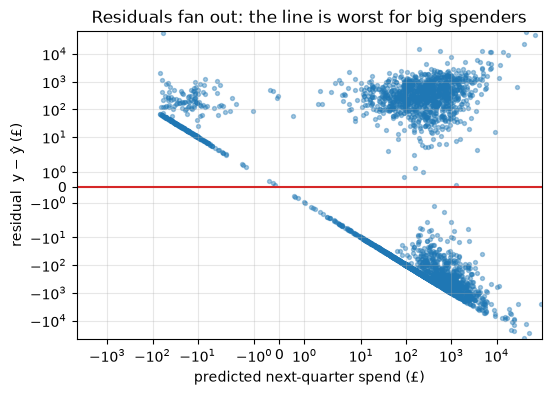

In [10]:
import matplotlib.pyplot as plt
pred = line.predict(cust[["spend"]])
plt.figure(figsize=(6, 4))
plt.scatter(pred, y_real - pred, s=8, alpha=.4)
plt.axhline(0, color="tab:red")
plt.xscale("symlog"); plt.yscale("symlog")
plt.xlabel("predicted next-quarter spend (£)"); plt.ylabel("residual  y − ŷ (£)")
plt.title("Residuals fan out: the line is worst for big spenders"); plt.grid(alpha=.3)
plt.show()

## Quiz answers

1. **RMSE and MAE** are in pounds. MSE is in pounds²; R² has no units.
2. When every residual has the same absolute size (e.g. all misses are exactly £5). Any unevenness makes RMSE larger.
3. $R^2 = 0$: the model's squared error equals the baseline's; it explains nothing. $R^2 < 0$: worse than predicting the mean.
4. **MAE**: it is the average miss in pounds, weighs every customer equally, and needs no explanation.
5. **MSE** (equivalently RMSE or the sum of squared residuals). That is why "least squares" is the name.

**Next:** [02.4 Gradient descent](../04-gradient-descent/)